# Errores Numéricos y Precisión Computacional

## Objetivos

En este laboratorio exploraremos experimentalmente:

La representación de números en punto flotante.
- Errores de redondeo.
- Errores absoluto y relativo.
- Error de truncamiento.
- Cancelación catastrófica.
- Acumulación de errores.
- Buenas prácticas en programación científica.

# Ejercicio 1. Representación en punto flotante
## Enunciado

Python almacena los números reales utilizando el estándar IEEE-754.

Observe cómo se representan internamente algunos números decimales.

In [ ]:

print("0.1 =", format(0.1, ".30f"))
print("0.2 =", format(0.2, ".30f"))
print("0.3 =", format(0.3, ".30f"))


0.1 = 0.100000000000000005551115123126
0.2 = 0.200000000000000011102230246252
0.3 = 0.299999999999999988897769753748


## Preguntas
1. ¿Alguno de los números se representa exactamente?
2. ¿Qué diferencias observa?
3. ¿Por qué ocurre esto?

# Ejercicio 2. Comparación de números flotantes
## Enunciado

Verifique si la suma de 0.1 y 0.2 es exactamente igual a 0.3.

In [2]:
import math

print(0.1 + 0.2)

print(0.1 + 0.2 == 0.3)

print(math.isclose(0.1 + 0.2, 0.3))

0.30000000000000004
False
True


## Preguntas
1. ¿Por qué == devuelve False?
2. ¿Qué hace math.isclose()?
3. ¿En qué situaciones sería preferible utilizar math.isclose()?

# Ejercicio 3. Error absoluto y error relativo
## Enunciado

Considere la aproximación

$π≈3.14$

Calcule:

- Error absoluto.
- Error relativo.
- Error porcentual.

In [3]:
import numpy as np

valor_real = np.pi
aproximacion = 3.14

error_absoluto = abs(valor_real - aproximacion)

error_relativo = error_absoluto / abs(valor_real)

error_porcentual = error_relativo * 100

print("Valor real:", valor_real)
print("Aproximación:", aproximacion)
print("Error absoluto:", error_absoluto)
print("Error relativo:", error_relativo)
print("Error porcentual:", error_porcentual, "%")

Valor real: 3.141592653589793
Aproximación: 3.14
Error absoluto: 0.0015926535897929917
Error relativo: 0.0005069573828972128
Error porcentual: 0.05069573828972128 %


## Preguntas
1. ¿Qué error es mayor?
2. ¿Cuál considera más útil para comparar aproximaciones?

# Ejercicio 4. Error de truncamiento
## Enunciado

La serie de Taylor de $e^{x}$ es:

$$e^{x} = \sum_{n=0}^{\infty}\frac{x^{n}}{n!}$$

Compare distintas aproximaciones para $x=1$.

In [4]:
import numpy as np
import math

x = 1

aprox1 = 1

aprox2 = 1 + x

aprox3 = 1 + x + x**2 / math.factorial(2)

aprox4 = aprox3 + x**3 / math.factorial(3)

aprox5 = aprox4 + x**4 / math.factorial(4)

valor_real = np.exp(x)

print("Valor real:", valor_real)

print("Orden 0:", aprox1)

print("Orden 1:", aprox2)

print("Orden 2:", aprox3)

print("Orden 3:", aprox4)

print("Orden 4:", aprox5)

Valor real: 2.718281828459045
Orden 0: 1
Orden 1: 2
Orden 2: 2.5
Orden 3: 2.6666666666666665
Orden 4: 2.708333333333333


## Preguntas
1. ¿Qué ocurre cuando aumenta el número de términos?
2. ¿Cómo cambia el error?

# Ejercicio 5. Graficando el error de truncamiento

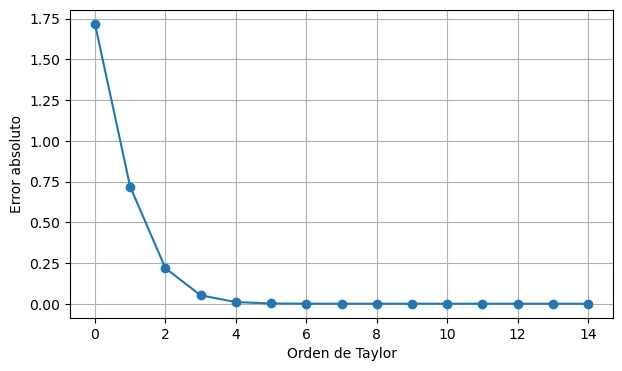

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

x = 1

valor_real = np.exp(x)

errores = []

orden = []

aproximacion = 0

for n in range(15):

    aproximacion += x**n / math.factorial(n)

    errores.append(abs(valor_real - aproximacion))

    orden.append(n)

plt.figure(figsize=(7,4))

plt.plot(orden, errores, marker='o')

plt.xlabel("Orden de Taylor")

plt.ylabel("Error absoluto")

plt.grid(True)

plt.show()

## Preguntas
1. ¿El error disminuye siempre?
2. ¿Qué tendencia observa?

# Ejercicio 6. Cancelación catastrófica
## Enunciado

Evalúe la siguiente expresión
$$ \sqrt{x+1}-\sqrt{x} $$
para un valor grande de $x$

In [2]:
import numpy as np

x = 1e8

resultado1 = np.sqrt(x + 1) - np.sqrt(x)

resultado2 = 1 / (np.sqrt(x + 1) + np.sqrt(x))

print("Forma original:", resultado1)

print("Forma reformulada:", resultado2)

Forma original: 5.000000055588316e-05
Forma reformulada: 4.9999999874999996e-05


## Preguntas
1. ¿Los resultados coinciden exactamente?
2. ¿Cuál considera más estable?
3. ¿Por qué?

# Ejercicio 7. Acumulación del error
## Enunciado

Sume el número 0.1 un millón de veces.

In [7]:
suma = 0

for i in range(1000000):

    suma += 0.1

print("Resultado:", suma)

print("Valor esperado:", 100000)

print("Diferencia:", suma - 100000)

Resultado: 100000.00000133288
Valor esperado: 100000
Diferencia: 1.3328826753422618e-06


## Preguntas
1. ¿La suma coincide exactamente?
2. ¿Por qué aparece una diferencia?

# Ejercicio 8. Precisión simple vs doble

In [8]:
import numpy as np

x32 = np.float32(np.pi)

x64 = np.float64(np.pi)

print("float32 =", x32)

print("float64 =", x64)

print("Error float32 =", abs(np.pi - x32))

print("Error float64 =", abs(np.pi - x64))

float32 = 3.1415927
float64 = 3.141592653589793
Error float32 = 0.0
Error float64 = 0.0


## Preguntas
1. ¿Qué tipo de dato conserva más cifras?
2. ¿Qué ventajas tiene utilizar float64?

# Ejercicio 9. Función para calcular errores
## Enunciado

Implemente una función que reciba un valor real y una aproximación y retorne:

- Error absoluto.
- Error relativo.
- Error porcentual.

In [ ]:
def calcular_error(valor_real, aproximacion):

    error_absoluto =

    error_relativo =

    error_porcentual =

    return error_absoluto, error_relativo, error_porcentual

Pruebe la función con

In [ ]:
calcular_error(np.pi, 3.14)

# Ejercicio 10. Análisis final
Considere las siguientes afirmaciones.

In [10]:
a = 0.1 + 0.2

b = 0.3

print(a)

print(b)

print(a == b)

0.30000000000000004
0.3
False


# Ejercicio adicional (Reto)

Implemente una función que aproxime

$$e^{x}$$

mediante la serie de Taylor utilizando un número arbitrario de términos.

La función debe tener la forma:

In [ ]:
def taylor_exp(x, n):
    """
    Aproxima e^x utilizando los primeros n términos
    de la serie de Taylor.

    Parámetros
    ----------
    x : float
        Valor donde se evalúa la función.
    n : int
        Número de términos de la serie.

    Retorna
    -------
    float
        Aproximación de e^x.
    """
    aproximacion = 0

    for k in range(n):
        # Complete esta parte
        pass

    return aproximacion

Pruebe la función para distintos valores de x y de n, y compare los resultados con numpy.exp(x).